# ANN Model Building

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

In [3]:
# Set random seed for reproducibility
np.random.seed(42)

In [4]:
df = pd.read_csv('fmnist_small.csv')
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0,7,0,50,205,196,213,165,0,0
1,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,142,142,142,21,0,3,0,0,0,0
3,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,8,0,0,0,0,0,0,0,0,0,...,213,203,174,151,188,10,0,0,0,0


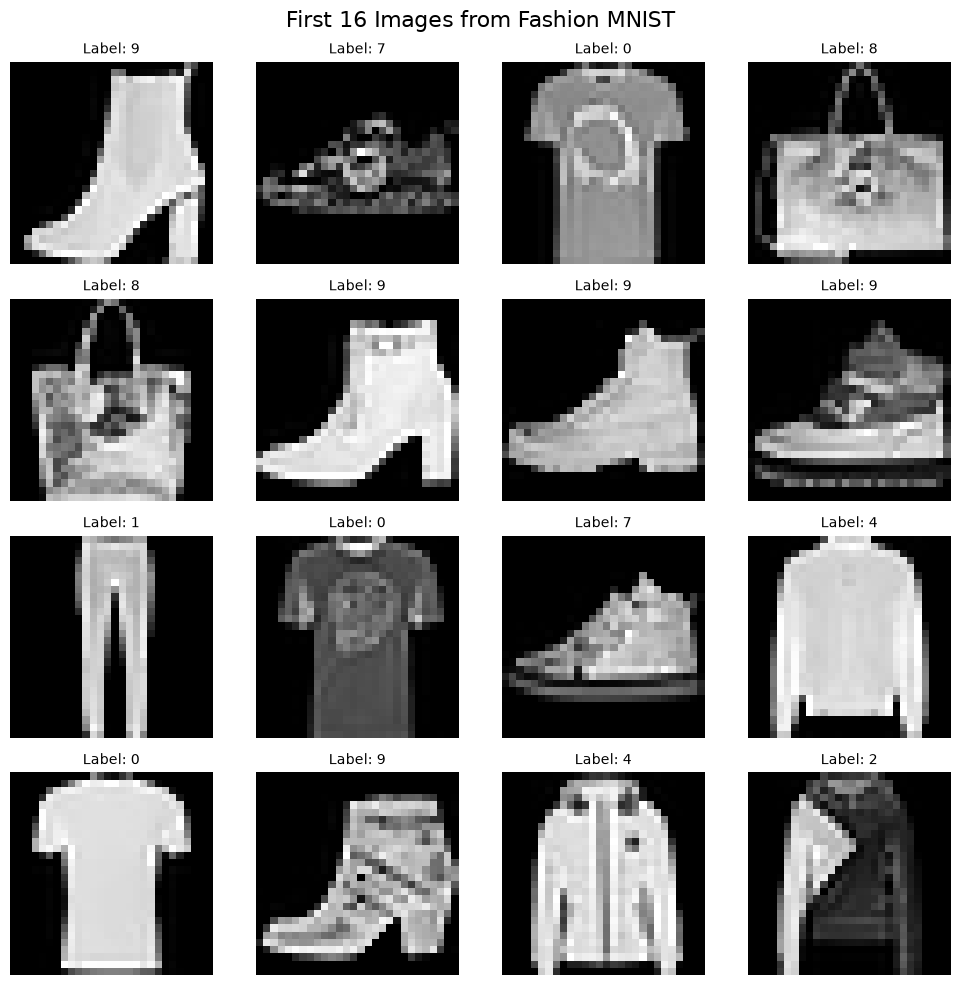

In [6]:
# Create a 4x4 grid of images
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle('First 16 Images from Fashion MNIST', fontsize=16)

# Plot the first 16 images
for i, ax in enumerate(axes.flat):
    index = i
    image = df.iloc[index, 1:].values.reshape(28, 28)  # Reshape to 28x28
    ax.imshow(image, cmap='gray')
    ax.axis('off')  # Hide axes
    ax.set_title(f'Label: {df.iloc[index, 0]}', fontsize=10)

plt.tight_layout()
plt.show()

In [7]:
# Train-test split

X = df.iloc[:, 1:].values  # Features (pixel values)
y = df.iloc[:, 0].values   # Labels

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
# Scale the pixel values to [0, 1] range

X_train = X_train / 255.0
X_test = X_test / 255.0

In [9]:
# Create a custom dataset class for PyTorch

class CustomDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]

In [10]:
# Crete train_dataset and test_dataset objects

train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)

In [11]:
# Create train and test data loaders

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Building the Architecture of the Neural Network

In [ ]:
# Define NN class 

class NeuralNetwork(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        # self.flatten = nn.Flatten()
        self.model = nn.Sequential(
            nn.Linear(num_features, 128),   # num_featureds = Input layer & 128 = Hidden layer 1
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)  # Assuming 10 classes for Fashion MNIST
        )

    def forward(self, x):
        return self.model(x)

In [13]:
# Setting the Training Pipelines

learning_rate = 0.001
num_epochs = 50

In [14]:
# Initialize the model
model = NeuralNetwork(num_features=X_train.shape[1])

# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [15]:
len(train_loader)  # Number of batches in the training set

150

In [16]:
# Training Loop

for epoch in range(num_epochs):

    total_epoch_loss = 0

    for batch_features, batch_labels in train_loader:

        # Forward pass
        outputs = model(batch_features)

        # Compute loss
        loss = criterion(outputs, batch_labels)

        # Backward pass and optimization
        optimizer.zero_grad() # For Clearing the gradients of all optimized tensors

        loss.backward()
        optimizer.step()

        # Calculate total loss for all epoch
        total_epoch_loss += loss.item()

    # Print average loss for the epoch
    avg_epoch_loss = total_epoch_loss / len(train_loader)
    
    print(f'Epoch [{epoch + 1}/{num_epochs}], Average Loss: {avg_epoch_loss:.4f}')

Epoch [1/50], Average Loss: 2.3000
Epoch [2/50], Average Loss: 2.2842
Epoch [3/50], Average Loss: 2.2700
Epoch [4/50], Average Loss: 2.2563
Epoch [5/50], Average Loss: 2.2423
Epoch [6/50], Average Loss: 2.2270
Epoch [7/50], Average Loss: 2.2100
Epoch [8/50], Average Loss: 2.1910
Epoch [9/50], Average Loss: 2.1695
Epoch [10/50], Average Loss: 2.1453
Epoch [11/50], Average Loss: 2.1176
Epoch [12/50], Average Loss: 2.0864
Epoch [13/50], Average Loss: 2.0512
Epoch [14/50], Average Loss: 2.0119
Epoch [15/50], Average Loss: 1.9684
Epoch [16/50], Average Loss: 1.9211
Epoch [17/50], Average Loss: 1.8701
Epoch [18/50], Average Loss: 1.8169
Epoch [19/50], Average Loss: 1.7624
Epoch [20/50], Average Loss: 1.7078
Epoch [21/50], Average Loss: 1.6542
Epoch [22/50], Average Loss: 1.6025
Epoch [23/50], Average Loss: 1.5532
Epoch [24/50], Average Loss: 1.5069
Epoch [25/50], Average Loss: 1.4637
Epoch [26/50], Average Loss: 1.4235
Epoch [27/50], Average Loss: 1.3863
Epoch [28/50], Average Loss: 1.3516
E

In [18]:
# Model Evaluation

model.eval()  # Set the model to evaluation mode


NeuralNetwork(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [24]:
# Model Accuracy Calculation

total = 0
correct = 0

with torch.no_grad():  # Disable gradient calculation for evaluation
    for batch_features, batch_labels in test_loader:
        outputs = model(batch_features) # This one is a Matrix
        _, predicted = torch.max(outputs.data, 1)  # Extracts the labels from the output matrix
        total += batch_labels.shape[0]  # Total number of samples
        correct += (predicted == batch_labels).sum().item()

print(f'Accuracy of the model on the {total} test images: {100 * correct / total:.2f}%')

Accuracy of the model on the 1200 test images: 65.75%
